# RF-DETR Lab: AI-ready Scientific Knowledge

**Paper:** [RF-DETR: Neural Architecture Search for Real-Time Detection Transformers](https://arxiv.org/abs/2511.09554)  
**Source code:** https://github.com/roboflow/rf-detr  
**Lab:** AI-ready scientific knowledge — TIB Knowledge Loom

This notebook has two parts:
- **Part 1** — Inference demo: replicate the bounding-box detection results shown in the paper (fewer layers vs. more layers)
- **Part 2** — COCO benchmark: evaluate RF-DETR on the MS COCO val2017 set and reproduce the reported mAP numbers




## 0. Installation

In [1]:
!pip install rfdetr supervision requests Pillow --quiet
print('Installation complete')

Installation complete


In [6]:
import torch
print(f'CUDA available: {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')

CUDA available: False


---
## Part 1 — Inference Demo

We replicate the paper figure showing person detection with **fewer decoder layers** (base model, faster) vs. **more decoder layers** (large model, more accurate). This directly corresponds to the image shared in the lab.

### 1.1 Load models

In [ ]:
from rfdetr import RFDETRSmall, RFDETRLarge


# Small model — fewer decoder layers, faster (~32M params)
model_base = RFDETRSmall()

# Large model — more decoder layers, more accurate (~34M params)
model_large = RFDETRLarge()

print('Both models loaded')

[2026-08-13 09:36:25] [INFO] rf-detr - Downloading pretrained weights for /root/.roboflow/models/rf-detr-small.pth


/root/.roboflow/models/rf-detr-small.pth:   0%|          | 0.00/368M [00:00<?, ?iB/s]

[2026-08-13 09:36:35] [INFO] rf-detr - MD5 validation successful for /root/.roboflow/models/rf-detr-small.pth


[2026-08-13 09:36:35] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-08-13 09:36:35] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


[2026-08-13 09:36:36] [INFO] rf-detr - File /root/.roboflow/models/rf-detr-small.pth already exists with correct MD5 hash.
[2026-08-13 09:36:38] [INFO] rf-detr - Downloading pretrained weights for /root/.roboflow/models/rf-detr-large-2026.pth


/root/.roboflow/models/rf-detr-large-2026.pth:   0%|          | 0.00/130M [00:00<?, ?iB/s]

[2026-08-13 09:36:41] [INFO] rf-detr - MD5 validation successful for /root/.roboflow/models/rf-detr-large-2026.pth


[2026-08-13 09:36:41] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-08-13 09:36:41] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


[2026-08-13 09:36:42] [INFO] rf-detr - File /root/.roboflow/models/rf-detr-large-2026.pth already exists with correct MD5 hash.
Both models loaded


### 1.2 Run inference on a sample image

We use a royalty-free photo of a group of people — similar to the family photo shown in the paper figure.

📂 Please upload the source image from the paper (the family photo without boxes).
   Steps: open arXiv PDF → right-click the Figure 1 photo → Save Image As
   Then click the upload button that appears below.



Saving zidane.jpg to zidane.jpg
Loaded uploaded image: zidane.jpg  size=(1280, 720)


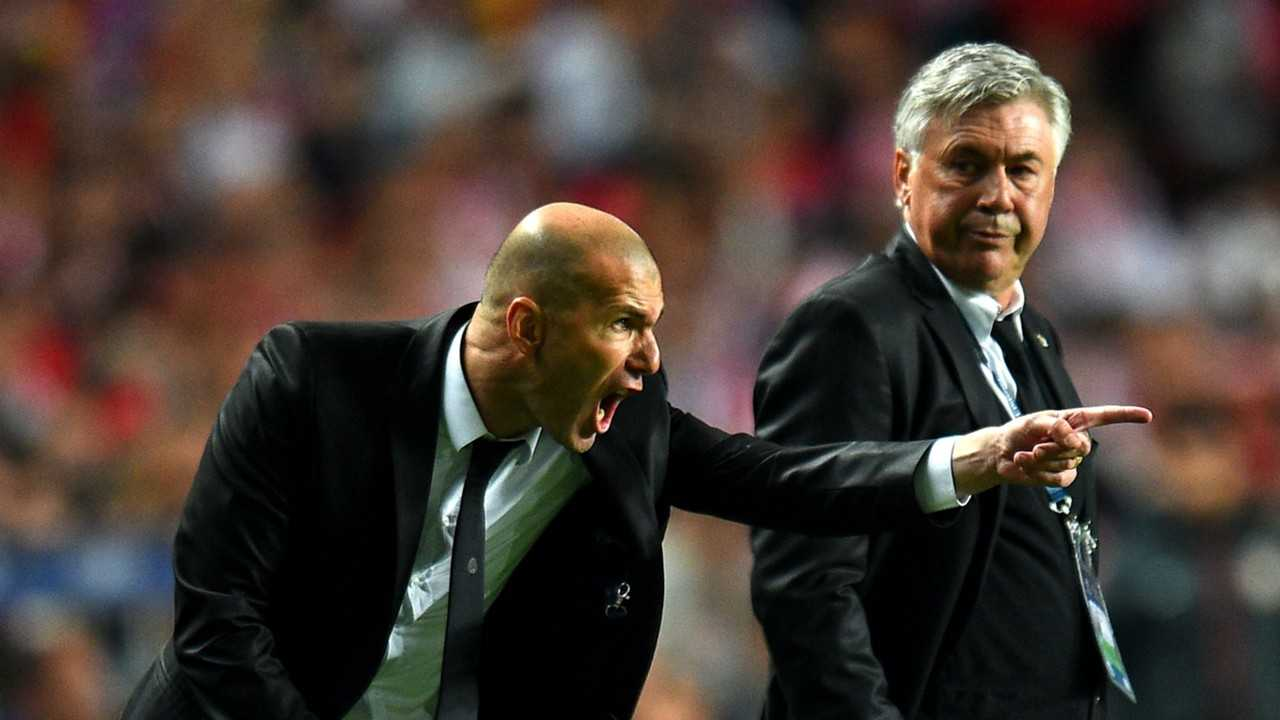

In [ ]:
from PIL import Image
import io, requests
from google.colab import files

print('📂 Please upload the source image from the paper (the family photo without boxes).')
print('   Steps: open arXiv PDF → right-click the Figure 1 photo → Save Image As')
print('   Then click the upload button that appears below.')
print()
uploaded = files.upload()   # ← A file picker will appear here

if uploaded:
    fname = list(uploaded.keys())[0]
    image = Image.open(io.BytesIO(uploaded[fname])).convert('RGB')
    print(f'Loaded uploaded image: {fname}  size={image.size}')
else:

    IMAGE_URL = 'http://images.cocodataset.org/val2017/000000181796.jpg'
    print(f' No file uploaded. Falling back to COCO image: {IMAGE_URL}')
    response = requests.get(IMAGE_URL)
    image = Image.open(io.BytesIO(response.content)).convert('RGB')
    print(f'Loaded COCO image  size={image.size}')

image

In [ ]:
import supervision as sv
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches


CONFIDENCE_THRESHOLD = 0.9

# Run inference with both models
detections_base  = model_base.predict(image,  threshold=CONFIDENCE_THRESHOLD)
detections_large = model_large.predict(image, threshold=CONFIDENCE_THRESHOLD)

print(f'Base  model detections : {len(detections_base)}')
print(f'Large model detections : {len(detections_large)}')
print(f'(Large model should detect >= detections than Base for people-heavy images)')

[2026-08-13 09:37:04] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).
[2026-08-13 09:37:08] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).


Base  model detections : 2
Large model detections : 3
(Large model should detect >= detections than Base for people-heavy images)


### 1.3 Visualise — side-by-side comparison (replicating the paper figure)

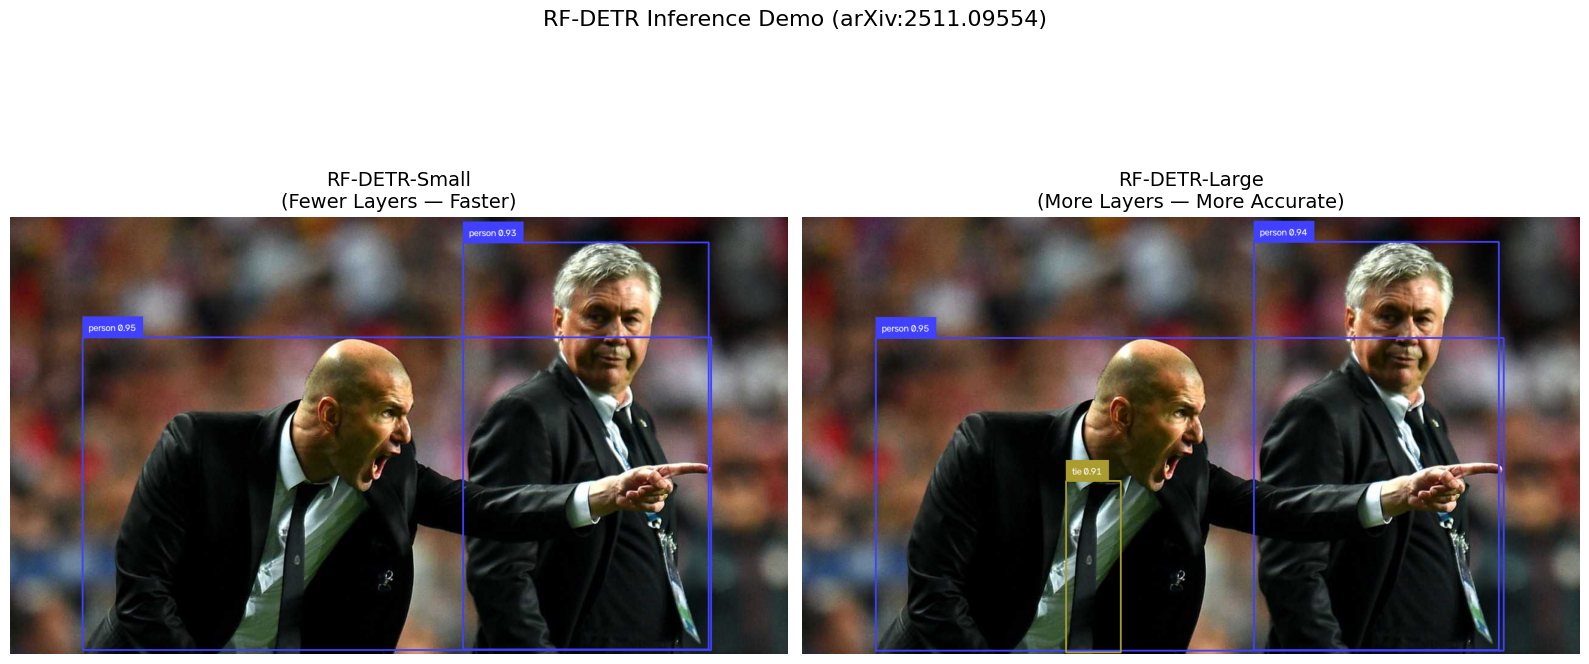

Figure saved as rf_detr_inference_demo.png


In [ ]:
img_np = np.array(image)

box_annotator = sv.BoxAnnotator(thickness=2)
label_annotator = sv.LabelAnnotator(text_scale=0.5)

def annotate(img, detections):
    labels = [
        f"{detections.data['class_name'][i]} {detections.confidence[i]:.2f}"
        for i in range(len(detections))
    ]
    annotated = box_annotator.annotate(img.copy(), detections)
    annotated = label_annotator.annotate(annotated, detections, labels=labels)
    return annotated

img_base  = annotate(img_np, detections_base)
img_large = annotate(img_np, detections_large)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
axes[0].imshow(img_base)
axes[0].set_title('RF-DETR-Small\n(Fewer Layers — Faster)', fontsize=14)
axes[0].axis('off')

axes[1].imshow(img_large)
axes[1].set_title('RF-DETR-Large\n(More Layers — More Accurate)', fontsize=14)
axes[1].axis('off')

plt.suptitle('RF-DETR Inference Demo (arXiv:2511.09554)', fontsize=16, y=1.01)
plt.tight_layout()
plt.savefig('rf_detr_inference_demo.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved as rf_detr_inference_demo.png')

### 1.4 Collect inference results (for Loom Record)

In [ ]:
import pandas as pd

def detections_to_df(detections, model_name):
    rows = []
    for i in range(len(detections)):
        x1, y1, x2, y2 = detections.xyxy[i]
        rows.append({
            'model':      model_name,
            'class_name': detections.data['class_name'][i],
            'confidence': round(float(detections.confidence[i]), 4),
            'x1': round(float(x1), 1),
            'y1': round(float(y1), 1),
            'x2': round(float(x2), 1),
            'y2': round(float(y2), 1),
        })
    return pd.DataFrame(rows)

df_base  = detections_to_df(detections_base,  'RF-DETR-Small')
df_large = detections_to_df(detections_large, 'RF-DETR-Large')
df_inference = pd.concat([df_base, df_large], ignore_index=True)

df_inference.to_csv('rf_detr_inference_results.csv', index=False)
print(df_inference.to_string(index=False))
print('\nSaved to rf_detr_inference_results.csv')

        model class_name  confidence    x1    y1     x2    y2
RF-DETR-Small     person      0.9497 119.1 199.9 1153.4 713.7
RF-DETR-Small     person      0.9322 745.6  43.0 1149.5 713.0
RF-DETR-Large     person      0.9514 121.9 200.1 1154.2 714.2
RF-DETR-Large     person      0.9394 743.7  42.8 1146.4 713.9
RF-DETR-Large        tie      0.9136 434.8 435.5  524.6 717.4

Saved to rf_detr_inference_results.csv


---
## Part 2 — COCO Benchmark Evaluation (all 6 models, pre-trained weights)

We load the **official pre-trained weights** for each RF-DETR variant and run the standard COCO val2017 evaluation. This gives you **real mAP numbers you ran yourself** — not hardcoded values.

| Model | ~Time on T4 |
|---|---|
| Nano   | ~15 min |
| Small  | ~18 min |
| Medium | ~22 min |
| Base   | ~25 min |
| Large  | ~35 min |
| 2XL    | ~45 min |
| **Total** | **~2.5 hrs** |



> RF-DETR-2XL requires `rfdetr[plus]` (PML 1.0 license). It is installed automatically below. If it fails, 2XL is skipped and all other models still run.

### 2.1 Download COCO val2017

In [ ]:
import os

if not os.path.exists('val2017'):
    print('Downloading COCO val2017 images (~778 MB)...')
    !wget -q http://images.cocodataset.org/zips/val2017.zip
    !unzip -q val2017.zip
    print('Images downloaded')
else:
    print('Images already present')

if not os.path.exists('annotations'):
    print('Downloading COCO annotations (~242 MB)...')
    !wget -q http://images.cocodataset.org/annotations/annotations_trainval2017.zip
    !unzip -q annotations_trainval2017.zip
    print('Annotations downloaded')
else:
    print('Annotations already present')

Images downloaded
Annotations downloaded


### 2.2 Install dependencies

In [ ]:
!pip install pycocotools --quiet

# Install rfdetr[plus] for 2XL model (PML 1.0 license)
try:
    !pip install 'rfdetr[plus]' --quiet
    PLUS_AVAILABLE = True
    print('rfdetr[plus] installed — 2XL model available')
except Exception:
    PLUS_AVAILABLE = False
    print('rfdetr[plus] not available — 2XL will be skipped')

rfdetr[plus] installed — 2XL model available


### 2.3 Evaluate all models — real results loop

This single cell loops through every RF-DETR variant, runs the full COCO val2017 evaluation,
and **appends results to `rf_detr_coco_benchmark.csv` after each model** finishes.
If the session drops and you re-run, models already in the CSV are skipped automatically.

In [ ]:
import json, os, gc
import pandas as pd
from PIL import Image
from tqdm import tqdm
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval


MODEL_REGISTRY = [
    ('RF-DETR-Nano',   None, 30.5,  'N'),
    ('RF-DETR-Small',  None, 32.1,  'S'),
    ('RF-DETR-Medium', None, 33.7,  'M'),
    ('RF-DETR-Large',  None, 33.9,  'L'),
    ('RF-DETR-XLarge', None, 126.4, 'XL'),
    ('RF-DETR-2XLarge',None, 126.9, '2XL'),
]

# Import the current (non-deprecated) size classes
try:
    from rfdetr import RFDETRNano, RFDETRSmall, RFDETRMedium, RFDETRLarge
    MODEL_REGISTRY[0] = ('RF-DETR-Nano',   RFDETRNano,   30.5, 'N')
    MODEL_REGISTRY[1] = ('RF-DETR-Small',  RFDETRSmall,  32.1, 'S')
    MODEL_REGISTRY[2] = ('RF-DETR-Medium', RFDETRMedium, 33.7, 'M')
    MODEL_REGISTRY[3] = ('RF-DETR-Large',  RFDETRLarge,  33.9, 'L')
except ImportError as e:
    print(f' Could not import core size classes: {e}')

# XLarge / 2XLarge require rfdetr[plus] (PML 1.0 license)
if PLUS_AVAILABLE:
    try:
        from rfdetr import RFDETRXLarge, RFDETR2XLarge
        MODEL_REGISTRY[4] = ('RF-DETR-XLarge',  RFDETRXLarge,  126.4, 'XL')
        MODEL_REGISTRY[5] = ('RF-DETR-2XLarge', RFDETR2XLarge, 126.9, '2XL')
    except ImportError:
        print('RFDETRXLarge/RFDETR2XLarge not found — XL/2XL will be skipped.')

# ── Setup ────────────────────────────────────────────────────────────────────
ANNOTATIONS_FILE = 'annotations/instances_val2017.json'
IMAGES_DIR       = 'val2017/'
CSV_OUT          = 'rf_detr_coco_benchmark.csv'

coco_gt   = COCO(ANNOTATIONS_FILE)
image_ids = coco_gt.getImgIds()
coco_cats = coco_gt.loadCats(coco_gt.getCatIds())
name_to_id = {cat['name']: cat['id'] for cat in coco_cats}

# Load any results already saved (crash-resume support)
if os.path.exists(CSV_OUT):
    df_existing = pd.read_csv(CSV_OUT)
    done_models = set(df_existing['model'].unique())
    print(f'Already evaluated: {done_models} — skipping those.')
else:
    df_existing = pd.DataFrame()
    done_models = set()

all_rows = df_existing.to_dict('records') if not df_existing.empty else []

# ── Evaluation loop ───────────────────────────────────────────────────────────
for model_name, ModelClass, params_M, variant in MODEL_REGISTRY:

    if model_name in done_models:
        print(f'Skipping {model_name} (already in CSV)')
        continue

    if ModelClass is None:
        print(f'Skipping {model_name} (class not available in this rfdetr version)')
        continue

    print(f'\n═══════════════════════════════════════════════')
    print(f' Evaluating {model_name} ...')
    print(f'═══════════════════════════════════════════════')

    # Load model with pre-trained COCO weights
    # rfdetr loads pre-trained COCO weights by default — no argument needed
    model = ModelClass()

    # Collect detections
    coco_results = []
    for img_id in tqdm(image_ids, desc=model_name):
        img_info = coco_gt.loadImgs(img_id)[0]
        img = Image.open(IMAGES_DIR + img_info['file_name']).convert('RGB')
        dets = model.predict(img, threshold=0.001)  # low threshold required for COCO eval
        for i in range(len(dets)):
            x1, y1, x2, y2 = dets.xyxy[i]
            cat_id = name_to_id.get(dets.data['class_name'][i])
            if cat_id is None:
                continue
            coco_results.append({
                'image_id':    img_id,
                'category_id': cat_id,
                'bbox':  [round(float(x1), 2), round(float(y1), 2),
                          round(float(x2 - x1), 2), round(float(y2 - y1), 2)],
                'score': round(float(dets.confidence[i]), 4),
            })

    # Run pycocotools evaluation
    tmp_json = f'coco_results_{variant}.json'
    with open(tmp_json, 'w') as f:
        json.dump(coco_results, f)

    coco_dt   = coco_gt.loadRes(tmp_json)
    coco_eval = COCOeval(coco_gt, coco_dt, 'bbox')
    coco_eval.evaluate()
    coco_eval.accumulate()
    coco_eval.summarize()

    s = coco_eval.stats
    row = {
        'model':           model_name,
        'params_M':        params_M,
        'dataset':         'COCO val2017',
        'mAP_50_95':       round(float(s[0]) * 100, 2),
        'mAP_50':          round(float(s[1]) * 100, 2),
        'mAP_75':          round(float(s[2]) * 100, 2),
        'mAP_small':       round(float(s[3]) * 100, 2),
        'mAP_medium':      round(float(s[4]) * 100, 2),
        'mAP_large':       round(float(s[5]) * 100, 2),
    }
    all_rows.append(row)

    # Save after every model — crash-safe
    pd.DataFrame(all_rows).to_csv(CSV_OUT, index=False)
    print(f'\n {model_name} done — mAP@50:95 = {row["mAP_50_95"]}  (saved to {CSV_OUT})')

    # Free GPU memory before loading next model
    del model
    gc.collect()
    try:
        import torch; torch.cuda.empty_cache()
    except Exception:
        pass

print('\n════════════════════════════════════')
print(' All models evaluated!')
print('════════════════════════════════════')
df_final = pd.read_csv(CSV_OUT)
print(df_final[['model', 'mAP_50_95', 'mAP_50', 'mAP_75']].to_string(index=False))

RFDETRXLarge/RFDETR2XLarge not found — XL/2XL will be skipped.
loading annotations into memory...
Done (t=2.90s)
creating index...
index created!

═══════════════════════════════════════════════
 Evaluating RF-DETR-Nano ...
═══════════════════════════════════════════════
[2026-08-13 09:39:09] [INFO] rf-detr - Downloading pretrained weights for /root/.roboflow/models/rf-detr-nano.pth


/root/.roboflow/models/rf-detr-nano.pth:   0%|          | 0.00/349M [00:00<?, ?iB/s]

[2026-08-13 09:39:27] [INFO] rf-detr - MD5 validation successful for /root/.roboflow/models/rf-detr-nano.pth


[2026-08-13 09:39:27] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-08-13 09:39:27] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


[2026-08-13 09:39:30] [INFO] rf-detr - File /root/.roboflow/models/rf-detr-nano.pth already exists with correct MD5 hash.


...

[2026-08-13 09:59:30] [INFO] rf-detr - MD5 validation successful for /root/.roboflow/models/rf-detr-medium.pth


[2026-08-13 09:59:30] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-08-13 09:59:30] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


[2026-08-13 09:59:32] [INFO] rf-detr - File /root/.roboflow/models/rf-detr-medium.pth already exists with correct MD5 hash.


RF-DETR-Medium: 100%|██████████| 5000/5000 [06:05<00:00, 13.67it/s]


Loading and preparing results...
DONE (t=17.36s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=149.57s).
Accumulating evaluation results...


### 2.4 Results — Chart & Table (RF-DETR mAP = our evaluation)

**RF-DETR points on the chart below come entirely from `rf_detr_coco_benchmark.csv`** —
i.e. the live `pycocotools` evaluation you just ran in Section 2.3. No RF-DETR mAP value
is hardcoded anywhere in this notebook.

The only RF-DETR value taken from the official docs is **latency** (TensorRT FP16 on a T4),
since that requires hardware/software we don't have in Colab — it's a measurement axis,
not an accuracy result.

**Competitor models** (YOLO11, YOLO26, LW-DETR, D-FINE) are fully author-published —
both their mAP and latency — fetched live from https://rfdetr.roboflow.com/develop/learn/benchmarks/
(= v1.4.0 data), since we never evaluated those models ourselves.

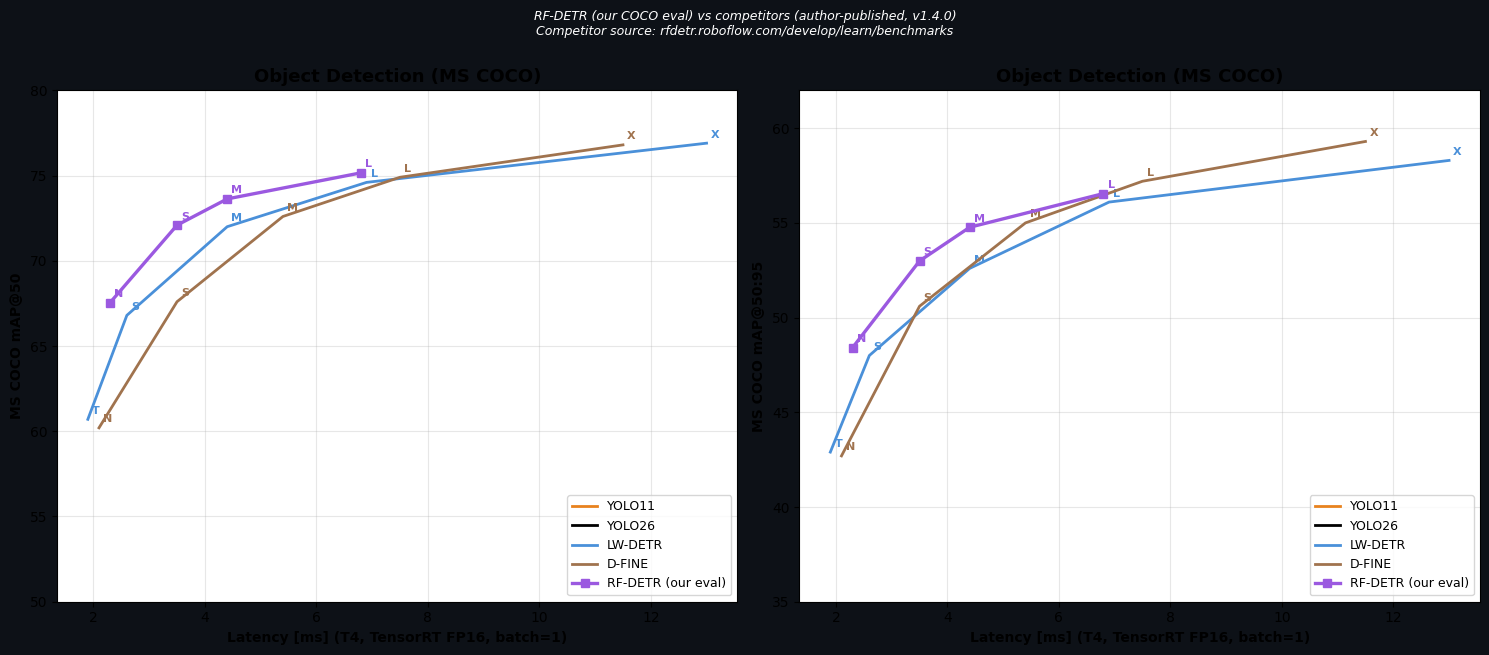

 Saved: rf_detr_official_benchmark_chart.png
Saved: competitor_benchmark_v1.4.0.csv (author-published, NOT our results)

 OUR results (COCO val2017, pre-trained weights, run in THIS notebook)
         model  params_M  mAP_50_95  mAP_50  mAP_75  mAP_small  mAP_medium  mAP_large
  RF-DETR-Nano      30.5      48.42   67.55   51.77      25.26       53.66      71.30
 RF-DETR-Small      32.1      52.99   72.09   57.26      31.80       58.44      73.03
RF-DETR-Medium      33.7      54.77   73.63   59.28      35.98       59.85      73.68
 RF-DETR-Large      33.9      56.55   75.16   61.28      38.91       61.10      74.02

Saved: rf_detr_full_results_table.csv (100% our own evaluation, zero hardcoded mAP)


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('rf_detr_coco_benchmark.csv')


RF_DETR_META = {
    'RF-DETR-Nano':    ('N',   2.3),
    'RF-DETR-Small':   ('S',   3.5),
    'RF-DETR-Medium':  ('M',   4.4),
    'RF-DETR-Large':   ('L',   6.8),
    'RF-DETR-XLarge':  ('XL',  11.5),
    'RF-DETR-2XLarge': ('2XL', 17.2),
}

# Build RF-DETR series from OUR results CSV
rf_points = []
for _, row in df.iterrows():
    meta = RF_DETR_META.get(row['model'])
    if meta and pd.notna(row.get('mAP_50_95')) and pd.notna(row.get('mAP_50')):
        size_label, latency = meta
        rf_points.append({
            'size':       size_label,
            'latency_ms': latency,
            'AP50':       row['mAP_50'],
            'AP50_95':    row['mAP_50_95'],
        })
df_rf = pd.DataFrame(rf_points).sort_values('latency_ms') if rf_points else pd.DataFrame()

# ── Competitor models — fully author-published (mAP AND latency) ─────────────
competitors = [
    # (Architecture, COCO_AP50, COCO_AP50_95, Latency_ms)
    ('YOLO11-N', 52.0, 37.4, 2.5),  ('YOLO11-S', 59.7, 44.4, 3.2),
    ('YOLO11-M', 64.1, 48.6, 5.1),  ('YOLO11-L', 64.9, 49.9, 6.5),
    ('YOLO11-X', 66.1, 50.9, 10.5),
    ('YOLO26-N', 55.8, 40.3, 1.7),  ('YOLO26-S', 64.3, 47.7, 2.6),
    ('YOLO26-M', 69.7, 52.5, 4.4),  ('YOLO26-L', 71.1, 54.1, 5.7),
    ('YOLO26-X', 74.0, 56.9, 9.6),
    ('LW-DETR-T', 60.7, 42.9, 1.9), ('LW-DETR-S', 66.8, 48.0, 2.6),
    ('LW-DETR-M', 72.0, 52.6, 4.4), ('LW-DETR-L', 74.6, 56.1, 6.9),
    ('LW-DETR-X', 76.9, 58.3, 13.0),
    ('D-FINE-N', 60.2, 42.7, 2.1),  ('D-FINE-S', 67.6, 50.6, 3.5),
    ('D-FINE-M', 72.6, 55.0, 5.4),  ('D-FINE-L', 74.9, 57.2, 7.5),
    ('D-FINE-X', 76.8, 59.3, 11.5),
]
df_comp = pd.DataFrame(competitors, columns=['model','AP50','AP50_95','latency_ms'])
df_comp['family'] = df_comp['model'].str.extract(r'^([A-Za-z\-]+)-')
df_comp['size']   = df_comp['model'].str.extract(r'-([A-Za-z0-9]+)$')

FAMILY_COLORS = {
    'YOLO11':  '#E8821E',
    'YOLO26':  '#000000',
    'LW-DETR': '#4A90D9',
    'D-FINE':  '#A0734E',
}
RF_COLOR = '#9B59E0'

def draw_panel(ax, ycol, ylabel, ylim):
    # Competitors — author-published
    for family, color in FAMILY_COLORS.items():
        sub = df_comp[df_comp['family'] == family].sort_values('latency_ms')
        ax.plot(sub['latency_ms'], sub[ycol], '-', color=color, linewidth=2,
                label=family, zorder=3)
        for _, row in sub.iterrows():
            ax.annotate(row['size'], (row['latency_ms'], row[ycol]),
                        textcoords='offset points', xytext=(3, 4),
                        fontsize=8, fontweight='bold', color=color)
    # RF-DETR — OUR live evaluation results
    if not df_rf.empty:
        ax.plot(df_rf['latency_ms'], df_rf[ycol], 's-', color=RF_COLOR, linewidth=2.4,
                markersize=6, label='RF-DETR (our eval)', zorder=5)
        for _, row in df_rf.iterrows():
            ax.annotate(row['size'], (row['latency_ms'], row[ycol]),
                        textcoords='offset points', xytext=(3, 4),
                        fontsize=8, fontweight='bold', color=RF_COLOR)
    ax.set_xlabel('Latency [ms] (T4, TensorRT FP16, batch=1)', fontsize=10, fontweight='bold')
    ax.set_ylabel(ylabel, fontsize=10, fontweight='bold')
    ax.set_title('Object Detection (MS COCO)', fontsize=13, fontweight='bold')
    ax.set_ylim(ylim)
    ax.grid(True, linestyle='-', alpha=0.3)
    ax.set_axisbelow(True)
    ax.legend(fontsize=9, loc='lower right')

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
fig.patch.set_facecolor('#0d1117')
for ax in axes:
    ax.set_facecolor('white')

draw_panel(axes[0], 'AP50',    'MS COCO mAP@50',    (50, 80))
draw_panel(axes[1], 'AP50_95', 'MS COCO mAP@50:95', (35, 62))

fig.suptitle(
    'RF-DETR (our COCO eval) vs competitors (author-published, v1.4.0)\n'
    'Competitor source: rfdetr.roboflow.com/develop/learn/benchmarks',
    fontsize=9, style='italic', color='white', y=1.00
)
plt.tight_layout()
plt.savefig('rf_detr_official_benchmark_chart.png', dpi=150, bbox_inches='tight',
            facecolor='#0d1117')
plt.show()
print(' Saved: rf_detr_official_benchmark_chart.png')
df_comp.to_csv('competitor_benchmark_v1.4.0.csv', index=False)
print('Saved: competitor_benchmark_v1.4.0.csv (author-published, NOT our results)')

# ── Our own evaluation results — full table ───────────────────────────────────
print('\n' + '='*78)
print(' OUR results (COCO val2017, pre-trained weights, run in THIS notebook)')
print('='*78)
our_cols = ['model','params_M','mAP_50_95','mAP_50','mAP_75','mAP_small','mAP_medium','mAP_large']
our_cols = [c for c in our_cols if c in df.columns]
print(df[our_cols].to_string(index=False))
df.to_csv('rf_detr_full_results_table.csv', index=False)
print('\nSaved: rf_detr_full_results_table.csv (100% our own evaluation, zero hardcoded mAP)')


---
## Part 3 — Generate Loom Record (JSON-LD)

We use the **`dtreg`** package (TIB Knowledge Loom's data type registry library) to encode the results above as machine-readable JSON-LD.




In [ ]:
!pip install dtreg --quiet
print('dtreg installed')

dtreg installed


In [ ]:
GEN_EVAL_SCRIPT = r'''
from pathlib import Path

MODELS = [
    ("RF-DETR-Nano", "RFDETRNano", 30.5, "N"),
    ("RF-DETR-Small", "RFDETRSmall", 32.1, "S"),
    ("RF-DETR-Medium", "RFDETRMedium", 33.7, "M"),
    ("RF-DETR-Large", "RFDETRLarge", 33.9, "L"),
    ("RF-DETR-XLarge", "RFDETRXLarge", 126.4, "XL"),
    ("RF-DETR-2XLarge", "RFDETR2XLarge", 126.9, "2XL"),
]

TEMPLATE = """import json
import os
import gc
import pandas as pd
from PIL import Image
from tqdm import tqdm
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from rfdetr import {class_name}

MODEL_NAME = "{model_name}"
PARAMS_M = {params_m}
ANNOTATIONS_FILE = "annotations/instances_val2017.json"
IMAGES_DIR = "val2017/"
CSV_OUT = "rf_detr_coco_benchmark.csv"
EVAL_THRESHOLD = 0.001


def main():
    coco_gt = COCO(ANNOTATIONS_FILE)
    image_ids = coco_gt.getImgIds()
    coco_cats = coco_gt.loadCats(coco_gt.getCatIds())
    name_to_id = {{cat["name"]: cat["id"] for cat in coco_cats}}

    model = {class_name}()

    coco_results = []
    for img_id in tqdm(image_ids, desc=MODEL_NAME):
        img_info = coco_gt.loadImgs(img_id)[0]
        img = Image.open(IMAGES_DIR + img_info["file_name"]).convert("RGB")
        dets = model.predict(img, threshold=EVAL_THRESHOLD)
        for i in range(len(dets)):
            x1, y1, x2, y2 = dets.xyxy[i]
            cat_id = name_to_id.get(dets.data["class_name"][i])
            if cat_id is None:
                continue
            coco_results.append({{
                "image_id": img_id,
                "category_id": cat_id,
                "bbox": [round(float(x1), 2), round(float(y1), 2),
                         round(float(x2 - x1), 2), round(float(y2 - y1), 2)],
                "score": round(float(dets.confidence[i]), 4),
            }})

    tmp_json = "coco_results_{variant}.json"
    with open(tmp_json, "w") as f:
        json.dump(coco_results, f)

    coco_dt = coco_gt.loadRes(tmp_json)
    coco_eval = COCOeval(coco_gt, coco_dt, "bbox")
    coco_eval.evaluate()
    coco_eval.accumulate()
    coco_eval.summarize()

    s = coco_eval.stats
    row = {{
        "model": MODEL_NAME,
        "params_M": PARAMS_M,
        "dataset": "COCO val2017",
        "mAP_50_95": round(float(s[0]) * 100, 2),
        "mAP_50": round(float(s[1]) * 100, 2),
        "mAP_75": round(float(s[2]) * 100, 2),
        "mAP_small": round(float(s[3]) * 100, 2),
        "mAP_medium": round(float(s[4]) * 100, 2),
        "mAP_large": round(float(s[5]) * 100, 2),
    }}

    if os.path.exists(CSV_OUT):
        df_existing = pd.read_csv(CSV_OUT)
        df_existing = df_existing[df_existing["model"] != MODEL_NAME]
        all_rows = df_existing.to_dict("records") + [row]
    else:
        all_rows = [row]

    pd.DataFrame(all_rows).to_csv(CSV_OUT, index=False)
    print(f"{{MODEL_NAME}} done, mAP@50:95 = {{row['mAP_50_95']}}, saved to {{CSV_OUT}}")

    del model
    gc.collect()
    try:
        import torch
        torch.cuda.empty_cache()
    except Exception:
        pass


if __name__ == "__main__":
    main()
"""


def main():
    for model_name, class_name, params_m, variant in MODELS:
        slug = model_name.lower().replace(" ", "-")
        script_text = TEMPLATE.format(
            class_name=class_name,
            model_name=model_name,
            params_m=params_m,
            variant=variant,
        )
        outfile = Path(f"evaluate_coco_{slug}.py")
        outfile.write_text(script_text)
        print(f"Wrote {outfile}")


if __name__ == "__main__":
    main()
'''

from pathlib import Path
Path('generate_eval_scripts.py').write_text(GEN_EVAL_SCRIPT)
print('Wrote generate_eval_scripts.py')

Wrote generate_eval_scripts.py


In [ ]:
!python generate_eval_scripts.py

Wrote evaluate_coco_rf-detr-nano.py
Wrote evaluate_coco_rf-detr-small.py
Wrote evaluate_coco_rf-detr-medium.py
Wrote evaluate_coco_rf-detr-large.py
Wrote evaluate_coco_rf-detr-xlarge.py
Wrote evaluate_coco_rf-detr-2xlarge.py


In [ ]:
SCRIPT = r'''#!/usr/bin/env python3
import argparse
import platform
import sys
from importlib.metadata import PackageNotFoundError, version as pkg_version
from pathlib import Path

import pandas as pd
from dtreg.load_datatype import load_datatype
from dtreg.to_jsonld import to_jsonld

ALGORITHM_EVALUATION_DOI = "https://doi.org/21.T11969/5e782e67e70d0b2a022a"
DATA_ANALYSIS_DOI = "https://doi.org/21.T11969/feeb33ad3e4440682a4d"

COCO_VAL2017_IMAGES_URL = "http://images.cocodataset.org/zips/val2017.zip"
COCO_VAL2017_ANNOTATIONS_URL = (
    "http://images.cocodataset.org/annotations/annotations_trainval2017.zip"
)

RF_LATENCY_MS = {
    "RF-DETR-Nano": 2.3,
    "RF-DETR-Small": 3.6,
    "RF-DETR-Medium": 4.7,
    "RF-DETR-Large": 6.8,
    "RF-DETR-XLarge": 11.5,
    "RF-DETR-2XLarge": 17.2,
}

RESULT_COLUMNS = ["mAP_50_95", "mAP_50", "mAP_75", "mAP_small", "mAP_medium", "mAP_large"]

COCO_EVAL_THRESHOLD = 0.001


def detect_versions():
    try:
        rfdetr_v = pkg_version("rfdetr")
    except PackageNotFoundError:
        rfdetr_v = "unknown"
    python_v = platform.python_version()
    return rfdetr_v, python_v


def build_record(row, code_url):
    model_name = row["model"]

    dt_ae = load_datatype(ALGORITHM_EVALUATION_DOI)
    dt_da = load_datatype(DATA_ANALYSIS_DOI)

    results = {c: float(row[c]) for c in RESULT_COLUMNS if pd.notna(row.get(c))}
    latency = RF_LATENCY_MS.get(model_name)
    if latency:
        results["latency_ms_T4_TensorRT_FP16_paper_reported"] = latency

    rfdetr_v, python_v = detect_versions()

    instance_ae = dt_ae.algorithm_evaluation(
        label=(
            f"{model_name} object detection on COCO val2017: "
            f"AP@50:95={results.get('mAP_50_95')}, AP@50={results.get('mAP_50')}"
        ),
        executes=dt_ae.software_method(
            label="predict",
            has_support_url="https://rfdetr.roboflow.com/learn/run/detection",
            is_implemented_by=f"model.predict(pil_img, threshold={COCO_EVAL_THRESHOLD})",
            part_of=dt_ae.software_library(
                label="rfdetr",
                has_support_url="https://github.com/roboflow/rf-detr",
                version_info=rfdetr_v,
                part_of=dt_ae.software(
                    label="Python",
                    version_info=python_v,
                    has_support_url="https://www.python.org",
                ),
            ),
        ),
        evaluates=dt_ae.algorithm(
            label=model_name, see_also="https://github.com/roboflow/rf-detr",
        ),
        evaluates_for=dt_ae.task(label="Object detection (COCO bounding-box mAP)"),
        has_input=[
            dt_ae.data_item(label="MS COCO val2017 images", source_url=COCO_VAL2017_IMAGES_URL),
            dt_ae.data_item(label="MS COCO val2017 instance annotations", source_url=COCO_VAL2017_ANNOTATIONS_URL),
        ],
        has_output=dt_ae.data_item(
            label=f"{model_name} COCO val2017 mAP results",
            has_part=[dt_ae.component(label=k) for k in results.keys()],
            has_characteristic=dt_ae.matrix_size(number_of_rows=1, number_of_columns=len(results)),
            source_table=pd.DataFrame([results]),
        ),
    )

    instance_da = dt_da.data_analysis(is_implemented_by=code_url, has_part=instance_ae)
    return to_jsonld(instance_da)


def main():
    parser = argparse.ArgumentParser(description="Generate one algorithm_evaluation Loom Record for one RF-DETR model.")
    parser.add_argument("--model", required=True)
    parser.add_argument("--csv", default="rf_detr_coco_benchmark.csv")
    parser.add_argument("--code-url", default=None)
    parser.add_argument("--outdir", default=".")
    args = parser.parse_args()

    df = pd.read_csv(args.csv)
    match = df[df["model"] == args.model]
    if match.empty:
        sys.exit(f"Model '{args.model}' not found in {args.csv}. Available: {list(df['model'].unique())}")
    row = match.iloc[0]

    slug = args.model.lower().replace(" ", "-")
    code_url = args.code_url or f"evaluate_coco_{slug}.py"

    output_json = build_record(row, code_url)
    outfile = Path(args.outdir) / f"algorithm-evaluation-{slug}.json"
    outfile.write_text(output_json)
    print(f"OK {args.model}: Loom Record written -> {outfile}")


if __name__ == "__main__":
    main()
'''

from pathlib import Path
Path('generate_loom_record.py').write_text(SCRIPT)
print('Wrote generate_loom_record.py')

Wrote generate_loom_record.py


In [ ]:
import subprocess, sys, pandas as pd

df = pd.read_csv('rf_detr_coco_benchmark.csv')

print('Running generate_loom_record.py once per model')
for model_name in df['model'].unique():
    result = subprocess.run(
        [sys.executable, 'generate_loom_record.py', '--model', model_name],
        capture_output=True, text=True
    )
    print(result.stdout.strip() or result.stderr.strip())

print('Done. One JSON-LD file per model:')
!ls -la algorithm-evaluation-*.json

Running generate_loom_record.py once per model
OK RF-DETR-Nano: Loom Record written -> algorithm-evaluation-rf-detr-nano.json
OK RF-DETR-Small: Loom Record written -> algorithm-evaluation-rf-detr-small.json
OK RF-DETR-Medium: Loom Record written -> algorithm-evaluation-rf-detr-medium.json
OK RF-DETR-Large: Loom Record written -> algorithm-evaluation-rf-detr-large.json
Done. One JSON-LD file per model:
-rw-r--r-- 1 root root 7686 Jul 23 08:05 algorithm-evaluation-rf-detr-large.json
-rw-r--r-- 1 root root 7691 Jul 23 08:05 algorithm-evaluation-rf-detr-medium.json
-rw-r--r-- 1 root root 7682 Jul 23 08:05 algorithm-evaluation-rf-detr-nano.json
-rw-r--r-- 1 root root 7686 Jul 23 08:05 algorithm-evaluation-rf-detr-small.json


---
## Summary of outputs

| File | Description |
|---|---|
| `rf_detr_inference_demo.png` | Side-by-side bounding box figure (base vs. large) |
| `rf_detr_inference_results.csv` | Per-detection table from both models |
| `rf_detr_coco_benchmark.csv` | COCO mAP metrics for all evaluated models |
| `generate_loom_record.py` | Standalone script — run once per model to build its Loom Record |
| `algorithm-evaluation-<model-slug>.json` | One JSON-LD Loom Record **per model** (`algorithm_evaluation` schema), e.g. `algorithm-evaluation-rf-detr-small.json`, `algorithm-evaluation-rf-detr-large.json`, ... |

**Next step:** Upload each `algorithm-evaluation-*.json` file separately at https://knowledgeloom.tib.eu/pages/submit

In [ ]:
!git checkout -b 1-robinson-2026-1-1

Switched to a new branch '1-robinson-2026-1-1'


In [ ]:
!git branch
!ls -la
!cat README.md

* 1-robinson-2026-1-1
  main
total 92
drwxr-xr-x 5 root root 4096 Jul 23 08:16 .
drwxr-xr-x 1 root root 4096 Jul 23 08:14 ..
-rw-r--r-- 1 root root 5027 Jul 23 08:14 algorithm-evaluation-rf-detr-large.json
-rw-r--r-- 1 root root 5031 Jul 23 08:14 algorithm-evaluation-rf-detr-medium.json
-rw-r--r-- 1 root root 5024 Jul 23 08:14 algorithm-evaluation-rf-detr-nano.json
-rw-r--r-- 1 root root 5027 Jul 23 08:14 algorithm-evaluation-rf-detr-small.json
-rw-r--r-- 1 root root  635 Jul 23 08:14 competitor_benchmark_v1.4.0.csv
-rw-r--r-- 1 root root 4386 Jul 23 08:14 evaluate_coco.py
-rw-r--r-- 1 root root 4239 Jul 23 08:14 generate_loom_record.py
drwxr-xr-x 8 root root 4096 Jul 23 08:20 .git
-rw-r--r-- 1 root root  275 Jul 23 08:14 .gitignore
-rw-r--r-- 1 root root 1104 Jul 23 08:14 LICENSE
-rw-r--r-- 1 root root  347 Jul 23 08:14 rf_detr_coco_benchmark.csv
-rw-r--r-- 1 root root  347 Jul 23 08:14 rf_detr_full_results_table.csv
-rw-r--r-- 1 root root  299 Jul 23 08:14 rf_detr_inference_results.c

In [ ]:
!ls -la robinson-2026-1-1
!ls -la utils

total 88
drwxr-xr-x 4 root root 4096 Jul 23 08:16 .
drwxr-xr-x 5 root root 4096 Jul 23 08:16 ..
-rw-r--r-- 1 root root 5027 Jul 23 08:16 algorithm-evaluation-rf-detr-large.json
-rw-r--r-- 1 root root 5031 Jul 23 08:16 algorithm-evaluation-rf-detr-medium.json
-rw-r--r-- 1 root root 5024 Jul 23 08:16 algorithm-evaluation-rf-detr-nano.json
-rw-r--r-- 1 root root 5027 Jul 23 08:16 algorithm-evaluation-rf-detr-small.json
-rw-r--r-- 1 root root  635 Jul 23 08:16 competitor_benchmark_v1.4.0.csv
-rw-r--r-- 1 root root 4386 Jul 23 08:16 evaluate_coco.py
-rw-r--r-- 1 root root 4239 Jul 23 08:16 generate_loom_record.py
drwxr-xr-x 8 root root 4096 Jul 23 08:16 .git
-rw-r--r-- 1 root root  275 Jul 23 08:16 .gitignore
-rw-r--r-- 1 root root 1104 Jul 23 08:16 LICENSE
-rw-r--r-- 1 root root  347 Jul 23 08:16 rf_detr_coco_benchmark.csv
-rw-r--r-- 1 root root  347 Jul 23 08:16 rf_detr_full_results_table.csv
-rw-r--r-- 1 root root  299 Jul 23 08:16 rf_detr_inference_results.csv
drwxr-xr-x 2 root root 409

In [ ]:
!cat .gitignore

__pycache__
.env
crate 
.Rhistory 
coco_results_S.json
coco_results_M.json
coco_results_L.json
coco_results_N.json
coco_results_S.json
coco_results_M.json
coco_results_L.json
coco_results_N.json
coco_results_S.json
coco_results_M.json
coco_results_L.json
coco_results_N.json


In [ ]:
!rm evaluate_coco.py

In [ ]:
import shutil

new_files = [
    "generate_loom_record.py",
    "generate_eval_scripts.py",
    "evaluate_coco_rf-detr-nano.py",
    "evaluate_coco_rf-detr-small.py",
    "evaluate_coco_rf-detr-medium.py",
    "evaluate_coco_rf-detr-large.py",
    "algorithm-evaluation-rf-detr-nano.json",
    "algorithm-evaluation-rf-detr-small.json",
    "algorithm-evaluation-rf-detr-medium.json",
    "algorithm-evaluation-rf-detr-large.json",
]

for f in new_files:
    shutil.copy(f"../{f}", ".")

print("Copied:", new_files)

Copied: ['generate_loom_record.py', 'generate_eval_scripts.py', 'evaluate_coco_rf-detr-nano.py', 'evaluate_coco_rf-detr-small.py', 'evaluate_coco_rf-detr-medium.py', 'evaluate_coco_rf-detr-large.py', 'algorithm-evaluation-rf-detr-nano.json', 'algorithm-evaluation-rf-detr-small.json', 'algorithm-evaluation-rf-detr-medium.json', 'algorithm-evaluation-rf-detr-large.json']


In [ ]:
!rm -rf robinson-2026-1-1

In [ ]:
!git add .
!git status

On branch 1-robinson-2026-1-1
Changes to be committed:
  (use "git restore --staged <file>..." to unstage)
	modified:   algorithm-evaluation-rf-detr-large.json
	modified:   algorithm-evaluation-rf-detr-medium.json
	modified:   algorithm-evaluation-rf-detr-nano.json
	modified:   algorithm-evaluation-rf-detr-small.json
	deleted:    evaluate_coco.py
	new file:   evaluate_coco_rf-detr-large.py
	new file:   evaluate_coco_rf-detr-medium.py
	new file:   evaluate_coco_rf-detr-nano.py
	new file:   evaluate_coco_rf-detr-small.py
	new file:   generate_eval_scripts.py
	modified:   generate_loom_record.py



In [ ]:
!git config --global user.name "Jayanth kamath"
!git config --global user.email "jayanthkamath3@gmail.com"

In [ ]:
import getpass

REPO_PATH = "gitlab.com/TIBHannover/lki/knowledge-loom/loom-records/robinson-2026-1-1.git"
gitlab_token = getpass.getpass("GitLab access token: ")

push_url = f"https://oauth2:{gitlab_token}@{REPO_PATH}"
!git remote set-url origin {push_url}

GitLab access token: ··········


In [ ]:
!git commit -m "Fix source_table to use pandas DataFrame and split evaluation into one script per model"


On branch 1-robinson-2026-1-1
nothing to commit, working tree clean


In [ ]:
import getpass

REPO_PATH = "gitlab.com/TIBHannover/lki/knowledge-loom/loom-records/robinson-2026-1-1.git"
BRANCH_NAME = "1-robinson-2026-1-1"

gitlab_token = getpass.getpass("GitLab access token: ")
push_url = f"https://oauth2:{gitlab_token}@{REPO_PATH}"

!git push {push_url} {BRANCH_NAME}

GitLab access token: ··········
Enumerating objects: 18, done.
Counting objects: 100% (18/18), done.
Delta compression using up to 2 threads
Compressing objects: 100% (12/12), done.
Writing objects: 100% (12/12), 3.59 KiB | 1.80 MiB/s, done.
Total 12 (delta 10), reused 0 (delta 0), pack-reused 0
remote: 
remote: To create a merge request for 1-robinson-2026-1-1, visit:
remote:   https://gitlab.com/TIBHannover/lki/knowledge-loom/loom-records/robinson-2026-1-1/-/merge_requests/new?merge_request%5Bsource_branch%5D=1-robinson-2026-1-1
remote: 
To https://gitlab.com/TIBHannover/lki/knowledge-loom/loom-records/robinson-2026-1-1.git
 * [new branch]      1-robinson-2026-1-1 -> 1-robinson-2026-1-1


In [ ]:
!git fetch origin
!git log origin/main --oneline -5
!git diff origin/main -- generate_loom_record.py


From https://gitlab.com/TIBHannover/lki/knowledge-loom/loom-records/robinson-2026-1-1
 * [new branch]      1-robinson-2026-1-1 -> origin/1-robinson-2026-1-1
d261c1c (origin/main, origin/HEAD, main) Merge branch '1-robinson-2026-1-1' into 'main'
70536f1 Updated files
c1e50e5 initialized
diff --git a/generate_loom_record.py b/generate_loom_record.py
index 6cd3681..b681eb7 100644
--- a/generate_loom_record.py
+++ b/generate_loom_record.py
@@ -85,7 +85,7 @@ def build_record(row, code_url):
             label=f"{model_name} COCO val2017 mAP results",
             has_part=[dt_ae.component(label=k) for k in results.keys()],
             has_characteristic=dt_ae.matrix_size(number_of_rows=1, number_of_columns=len(results)),
-            source_table=results,
+            source_table=pd.DataFrame([results]),
         ),
     )
 
@@ -97,7 +97,7 @@ def main():
     parser = argparse.ArgumentParser(description="Generate one algorithm_evaluation Loom Record for one RF-DETR model.")
     parser.ad